# Detecção de Fraude em Pagamentos — Análise Exploratória

**Amanda Gondra** · projeto completo em
[github.com/amanda-gondra/payment-fraud-detection](https://github.com/amanda-gondra/payment-fraud-detection)

## 1. Introdução e objetivo

O projeto constrói um modelo que estima, para cada transação de cartão, a probabilidade de ser
fraude e recomenda uma de três decisões: **aprovar**, **mandar para revisão humana** ou
**bloquear**. Antes de treinar qualquer modelo, esta análise responde a uma pergunta:
**o que diferencia uma transação fraudulenta de uma legítima nesta base?**

A investigação segue seis frentes:

- **Distribuição geral:** quão rara é a fraude e como ela varia no tempo.
- **Horário:** a que horas, e em que dias, as fraudes acontecem.
- **Categoria:** em que tipos de lojista elas se concentram.
- **Valor:** quanto custam as fraudes em comparação com as compras legítimas.
- **Distância:** quão longe do endereço do cliente fica o lojista.
- **Histórico do cartão:** como o cartão se comportava antes da fraude.

Uma regra vale para o notebook inteiro: **todo cálculo de histórico usa só o que era conhecido
antes da transação analisada**. Um sinal que enxerga o futuro parece ótimo na análise e não
funciona quando o modelo encontra uma transação nova.

Nenhum modelo é treinado aqui. O resultado desta fase são evidências e hipóteses para a próxima.

## 2. Origem, licença e descrição da base

| Item | Descrição |
| --- | --- |
| Base | [Credit Card Transactions Fraud Detection Dataset](https://www.kaggle.com/datasets/kartik2112/fraud-detection) (`kartik2112/fraud-detection`), versão 1, publicada em 05/08/2020 |
| Licença | CC0: Public Domain |
| Natureza | Transações **simuladas** com a ferramenta Sparkov: nenhuma pessoa real aparece nos dados |
| Arquivos | `fraudTrain.csv` (01/01/2019 a 21/06/2020, 1.296.675 transações) e `fraudTest.csv` (21/06/2020 a 31/12/2020, 555.719 transações) |
| Cobertura | 999 cartões, 693 lojistas e 14 categorias nos dois arquivos |

A página do Kaggle fala em cerca de 1.000 clientes e 800 lojistas. Os números da tabela foram
medidos no [perfil dos dados](https://github.com/amanda-gondra/payment-fraud-detection/blob/main/reports/data-profile.md)
do projeto, que também confirmou que não há valores ausentes nem linhas repetidas.

**Este notebook usa só o arquivo de treino.** O arquivo de teste fica guardado para a avaliação
final do modelo: se ele influenciasse as escolhas desta análise, a avaliação final sairia
otimista.

**Minimização de dados.** Só as colunas necessárias são lidas: data e hora, número do cartão,
categoria, valor, coordenadas do cliente e do lojista e o rótulo `is_fraud`. Nome, endereço,
profissão, data de nascimento, gênero e cidade não são carregados. O número do cartão vira um
identificador interno sequencial logo na leitura e é descartado; nenhuma tabela ou gráfico
mostra dados de uma pessoa.

## 3. Importação e preparação dos dados

O código abaixo:

1. encontra o arquivo, tanto no Kaggle (`/kaggle/input`) quanto no repositório (`data/raw/`);
2. confere o SHA-256 do arquivo com o manifesto do projeto, para garantir que esta análise usa
   exatamente os mesmos dados das outras etapas;
3. lê só as colunas necessárias e troca o número do cartão por um identificador interno;
4. ordena as transações por cartão e por data e hora, com ordenação estável: transações no mesmo
   segundo mantêm a ordem do arquivo (decisão D6 do projeto).

In [1]:
from __future__ import annotations

import hashlib
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

TRAIN_FILE_NAME = "fraudTrain.csv"
# SHA-256 recorded in data/manifest.json of the project (version 1 of the Kaggle dataset).
EXPECTED_SHA256 = "fd7139200dbfcbed0b6742bbe05a4f1abce532c4fef20918228a651647a3e75d"
COLUMNS = {
    "trans_date_trans_time": "timestamp",
    "cc_num": "card_number",
    "category": "category",
    "amt": "amount",
    "lat": "lat",
    "long": "long",
    "merch_lat": "merch_lat",
    "merch_long": "merch_long",
    "is_fraud": "is_fraud",
}
EARTH_RADIUS_KM = 6371.0088


def find_data_dir() -> Path:
    """Folder with fraudTrain.csv: the Kaggle input or the repository's data/raw/."""
    for base in (Path("/kaggle/input"), Path("../data/raw"), Path("data/raw")):
        if base.is_dir():
            found = sorted(base.rglob(TRAIN_FILE_NAME))
            if found:
                return found[0].parent
    raise FileNotFoundError(
        f"{TRAIN_FILE_NAME} not found: add the Kaggle dataset kartik2112/fraud-detection "
        "or run python -m pipeline.download in the repository"
    )


def sha256(path: Path) -> str:
    """SHA-256 of a file, read in 1 MB blocks."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


train_file = find_data_dir() / TRAIN_FILE_NAME
if sha256(train_file) != EXPECTED_SHA256:
    raise ValueError(f"{TRAIN_FILE_NAME} differs from the file recorded in the project manifest")
print(f"{TRAIN_FILE_NAME}: SHA-256 confere com o manifesto do projeto")

transactions = pd.read_csv(
    train_file,
    engine="pyarrow",
    usecols=list(COLUMNS),
    parse_dates=["trans_date_trans_time"],
).rename(columns=COLUMNS)
# The card number becomes an internal sequential id and is dropped right away.
transactions["card_id"] = pd.factorize(transactions["card_number"])[0]
transactions = (
    transactions.drop(columns="card_number")
    .sort_values(["card_id", "timestamp"], kind="stable")
    .reset_index(drop=True)
)
transactions["hour"] = transactions["timestamp"].dt.hour
transactions["weekday"] = transactions["timestamp"].dt.day_of_week
transactions["month"] = transactions["timestamp"].dt.to_period("M")

display(transactions[["timestamp", "card_id", "category", "amount", "is_fraud"]].head())

fraudTrain.csv: SHA-256 confere com o manifesto do projeto


,timestamp,card_id,category,amount,is_fraud
0,2019-01-01 00:00:18,0,misc_net,4.97,0
1,2019-01-01 16:53:34,0,kids_pets,114.79,0
2,2019-01-01 23:02:37,0,kids_pets,16.55,0
3,2019-01-03 01:40:38,0,misc_net,27.70,0
4,2019-01-03 15:24:11,0,entertainment,43.72,0


### Funções de apoio

Todas as taxas de fraude do notebook vêm da mesma função, `fraud_rate_by`. Para cada grupo, ela
dá:

- **taxa de fraude:** fraudes divididas pelas transações *do próprio grupo*. É o denominador
  correto: comparar só a quantidade de fraudes favorece os grupos com mais transações;
- **intervalo de confiança de 95%:** calculado pelo método de Wilson, que funciona bem com
  proporções pequenas como estas;
- **lift:** a taxa do grupo dividida pela taxa geral. Lift 3 quer dizer três vezes mais fraude
  que a média;
- **participação nas fraudes:** a fração de todas as fraudes da base que cai no grupo.

In [2]:
LEGIT_COLOR, FRAUD_COLOR = "#2a78d6", "#eb6834"
INK, INK_SECONDARY, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE, EMPTY = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"
CLASS_LABELS = {0: "Legítima", 1: "Fraude"}
CLASS_COLORS = {"Legítima": LEGIT_COLOR, "Fraude": FRAUD_COLOR}
WEEKDAYS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
PT_BR = str.maketrans(",.", ".,")

sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)


def fmt_int(value: float) -> str:
    return f"{value:,.0f}".translate(PT_BR)


def fmt_dec(value: float, places: int = 2) -> str:
    return f"{value:,.{places}f}".translate(PT_BR)


def fmt_pct(value: float, places: int = 2) -> str:
    return f"{value:.{places}%}".translate(PT_BR)


def percent_axis(ax: plt.Axes, axis: str = "y", places: int = 1) -> None:
    formatter = mticker.FuncFormatter(lambda value, _: fmt_pct(value, places))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


def thousands_axis(ax: plt.Axes, axis: str = "y") -> None:
    formatter = mticker.FuncFormatter(lambda value, _: fmt_int(value))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


def wilson_interval(frauds: pd.Series, total: pd.Series, z: float = 1.96) -> tuple:
    """95% Wilson score interval for a proportion."""
    k, n = frauds.to_numpy(float), total.to_numpy(float)
    p = k / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return np.clip(center - half, 0, 1), np.clip(center + half, 0, 1)


OVERALL_RATE = transactions["is_fraud"].mean()
TOTAL_FRAUDS = int(transactions["is_fraud"].sum())


def fraud_rate_by(frame: pd.DataFrame, key) -> pd.DataFrame:
    """Transactions, frauds, fraud rate with a 95% interval, lift and share of all frauds."""
    table = frame.groupby(key, observed=True)["is_fraud"].agg(transactions="size", frauds="sum")
    table["rate"] = table["frauds"] / table["transactions"]
    table["low"], table["high"] = wilson_interval(table["frauds"], table["transactions"])
    table["lift"] = table["rate"] / OVERALL_RATE
    table["share_of_frauds"] = table["frauds"] / TOTAL_FRAUDS
    return table


def show_rates(table: pd.DataFrame, index_name: str) -> pd.DataFrame:
    """The output of fraud_rate_by, formatted for reading."""
    shown = pd.DataFrame(
        {
            "Transações": table["transactions"].map(fmt_int),
            "Fraudes": table["frauds"].map(fmt_int),
            "Taxa de fraude": table["rate"].map(fmt_pct),
            "IC 95%": [
                f"{fmt_pct(low)} a {fmt_pct(high)}"
                for low, high in zip(table["low"], table["high"], strict=True)
            ],
            "Lift": table["lift"].map(lambda value: fmt_dec(value, 1)),
            "% das fraudes": table["share_of_frauds"].map(lambda value: fmt_pct(value, 1)),
        }
    )
    shown.index = shown.index.astype(str)
    shown.index.name = index_name
    return shown


def rate_bars(ax: plt.Axes, table: pd.DataFrame, labels: list[str], legend: bool = True) -> None:
    """Fraud rate per group as bars, with the 95% interval and the overall rate as reference."""
    positions = np.arange(len(table))
    errors = [table["rate"] - table["low"], table["high"] - table["rate"]]
    ax.bar(positions, table["rate"], color=FRAUD_COLOR, width=0.7, yerr=errors,
           ecolor=INK_SECONDARY, capsize=2, error_kw={"linewidth": 0.8},
           label="Taxa de fraude (IC 95%)")
    ax.axhline(OVERALL_RATE, color=INK_SECONDARY, linestyle="--", linewidth=1,
               label=f"Média geral ({fmt_pct(OVERALL_RATE)})")
    ax.set_xticks(positions, labels)
    percent_axis(ax)
    ax.grid(axis="x", visible=False)
    if legend:
        ax.set_ylim(0, table["high"].max() * 1.3)  # headroom so the legend sits above the bars
        ax.legend(loc="upper right", fontsize=9)

## 4. Visão geral e qualidade dos dados

In [3]:
quality = pd.DataFrame(
    {
        "Tipo": transactions.dtypes.astype(str),
        "Ausentes": transactions.isna().sum().map(fmt_int),
        "Valores distintos": transactions.nunique().map(fmt_int),
    }
)
display(quality)

overview = pd.Series(
    {
        "Transações": fmt_int(len(transactions)),
        "Cartões": fmt_int(transactions["card_id"].nunique()),
        "Categorias": fmt_int(transactions["category"].nunique()),
        "Primeira transação": transactions["timestamp"].min().strftime("%d/%m/%Y %H:%M:%S"),
        "Última transação": transactions["timestamp"].max().strftime("%d/%m/%Y %H:%M:%S"),
        "Transações por cartão (mediana)": fmt_int(transactions.groupby("card_id").size().median()),
    },
    name="Arquivo de treino",
)
display(overview.to_frame())

,Tipo,Ausentes,Valores distintos
timestamp,datetime64[s],0,1.274.791
category,str,0,14
amount,float64,0,52.928
lat,float64,0,968
long,float64,0,969
merch_lat,float64,0,1.247.805
merch_long,float64,0,1.275.745
is_fraud,int64,0,2
card_id,int64,0,983
hour,int32,0,24


,Arquivo de treino
Transações,1.296.675
Cartões,983
Categorias,14
Primeira transação,01/01/2019 00:00:18
Última transação,21/06/2020 12:13:37
Transações por cartão (mediana),1.054


Nenhuma das colunas carregadas tem valores ausentes. O arquivo de treino cobre 983 cartões e
14 categorias, de 01/01/2019 a 21/06/2020, com mediana de 1.054 transações por cartão.

A verificação completa de qualidade está no
[perfil dos dados](https://github.com/amanda-gondra/payment-fraud-detection/blob/main/reports/data-profile.md):

- não há linhas repetidas nem identificadores de transação repetidos;
- nenhum valor é menor ou igual a zero e nenhuma coordenada está fora da faixa válida;
- a coluna `unix_time` não marca o mesmo instante que a data e hora da transação (fica cerca
  de 7 anos antes), por isso não é usada.

Há, porém, um cuidado: o arquivo **não está em ordem de data e hora**, e há 20 grupos de
transações do mesmo cartão no mesmo segundo. Daí a ordenação estável feita na preparação.

## 5. Distribuição geral das fraudes

In [4]:
summary = pd.Series(
    {
        "Transações": fmt_int(len(transactions)),
        "Fraudes": fmt_int(TOTAL_FRAUDS),
        "Taxa de fraude": fmt_pct(OVERALL_RATE),
        "Legítimas por fraude": fmt_int((len(transactions) - TOTAL_FRAUDS) / TOTAL_FRAUDS),
        "Acerto de quem aprova tudo": fmt_pct(1 - OVERALL_RATE),
    },
    name="Arquivo de treino",
)
display(summary.to_frame())

,Arquivo de treino
Transações,1.296.675
Fraudes,7.506
Taxa de fraude,"0,58%"
Legítimas por fraude,172
Acerto de quem aprova tudo,"99,42%"


São **7.506 fraudes em 1.296.675 transações: 0,58%**, ou uma fraude para cada 172 transações
legítimas. Esse desbalanceamento define como o modelo vai ser avaliado: um "modelo" que aprova
tudo acerta 99,42% das vezes e não pega nenhuma fraude. Por isso a acurácia não serve como
métrica; as próximas fases usam a área sob a curva de precisão e revocação (PR-AUC), a revocação
com precisão fixa e o custo dos erros.

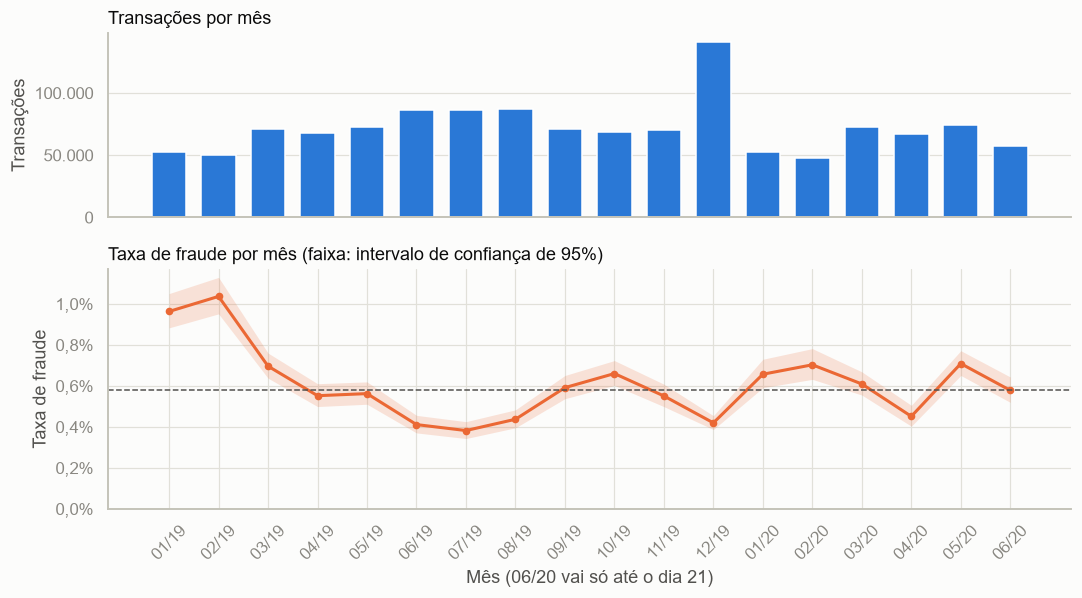

,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Mês,,,,,,
2019-01,52.525,506,"0,96%","0,88% a 1,05%","1,7","6,7%"
2019-02,49.866,517,"1,04%","0,95% a 1,13%","1,8","6,9%"
2019-03,70.939,494,"0,70%","0,64% a 0,76%","1,2","6,6%"
2019-04,68.078,376,"0,55%","0,50% a 0,61%","1,0","5,0%"
2019-05,72.532,408,"0,56%","0,51% a 0,62%","1,0","5,4%"
2019-06,86.064,354,"0,41%","0,37% a 0,46%","0,7","4,7%"
2019-07,86.596,331,"0,38%","0,34% a 0,43%","0,7","4,4%"
2019-08,87.359,382,"0,44%","0,40% a 0,48%","0,8","5,1%"
2019-09,70.652,418,"0,59%","0,54% a 0,65%","1,0","5,6%"


In [5]:
monthly = fraud_rate_by(transactions, "month")
month_labels = [period.strftime("%m/%y") for period in monthly.index]
positions = np.arange(len(monthly))

fig, (ax_volume, ax_rate) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True,
                                         gridspec_kw={"height_ratios": [1, 1.3]})
ax_volume.bar(positions, monthly["transactions"], color=LEGIT_COLOR, width=0.7)
ax_volume.set_title("Transações por mês")
ax_volume.set_ylabel("Transações")
thousands_axis(ax_volume)
ax_volume.grid(axis="x", visible=False)

ax_rate.plot(positions, monthly["rate"], color=FRAUD_COLOR, linewidth=2, marker="o", markersize=4)
ax_rate.fill_between(positions, monthly["low"], monthly["high"], color=FRAUD_COLOR, alpha=0.18,
                     linewidth=0)
ax_rate.axhline(OVERALL_RATE, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax_rate.set_title("Taxa de fraude por mês (faixa: intervalo de confiança de 95%)")
ax_rate.set_ylabel("Taxa de fraude")
ax_rate.set_ylim(0, None)
percent_axis(ax_rate)
ax_rate.set_xticks(positions, month_labels, rotation=45)
ax_rate.set_xlabel("Mês (06/20 vai só até o dia 21)")
fig.tight_layout()
plt.show()

display(show_rates(monthly, "Mês"))

A quantidade de fraudes por mês é relativamente estável (de 331 a 592), mas o volume de
transações não é. Por isso a taxa varia de **0,38% (07/2019) a 1,04% (02/2019)**.

Dezembro de 2019 mostra bem o efeito: o volume dobra (141.060 transações) e as fraudes sobem
menos (592), então a taxa cai para 0,42%. A variação da taxa vem mais do denominador do que de
uma mudança no ritmo das fraudes.

Para o modelo, isso tem duas consequências:

- os resultados precisam ser mostrados por período, não só no total;
- um limite de decisão calibrado num mês pode não servir para outro.

## 6. Análise por horário

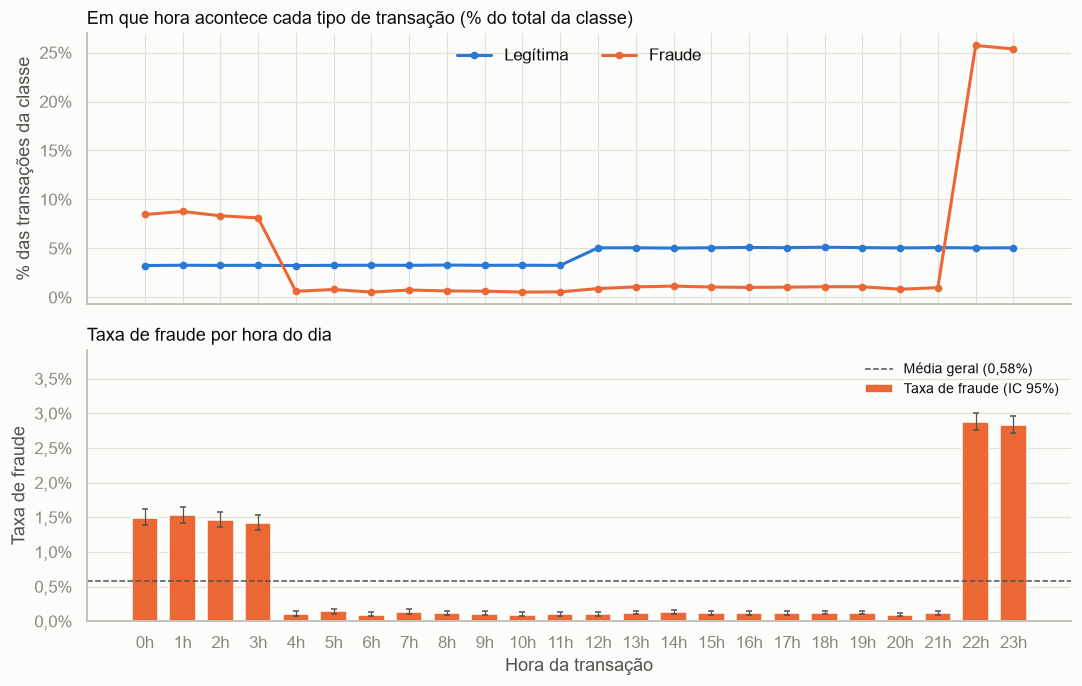

Transações entre 22h e 3h59: 23,2% das legítimas e 84,8% das fraudes


,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Hora,,,,,,
0,42.502,635,"1,49%","1,38% a 1,61%","2,6","8,5%"
1,42.869,658,"1,53%","1,42% a 1,66%","2,7","8,8%"
2,42.656,625,"1,47%","1,36% a 1,58%","2,5","8,3%"
3,42.769,609,"1,42%","1,32% a 1,54%","2,5","8,1%"
4,41.863,46,"0,11%","0,08% a 0,15%","0,2","0,6%"
5,42.171,60,"0,14%","0,11% a 0,18%","0,2","0,8%"
6,42.300,40,"0,09%","0,07% a 0,13%","0,2","0,5%"
7,42.203,56,"0,13%","0,10% a 0,17%","0,2","0,7%"
8,42.505,49,"0,12%","0,09% a 0,15%","0,2","0,7%"


In [6]:
by_hour = fraud_rate_by(transactions, "hour")
hour_share = (
    transactions.groupby(["is_fraud", "hour"]).size()
    .groupby(level="is_fraud").transform(lambda counts: counts / counts.sum())
    .unstack("is_fraud")
)

fig, (ax_share, ax_rate) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
for label, column in ((CLASS_LABELS[0], 0), (CLASS_LABELS[1], 1)):
    ax_share.plot(hour_share.index, hour_share[column], color=CLASS_COLORS[label], linewidth=2,
                  marker="o", markersize=4, label=label)
ax_share.set_title("Em que hora acontece cada tipo de transação (% do total da classe)")
ax_share.set_ylabel("% das transações da classe")
percent_axis(ax_share, places=0)
ax_share.legend(loc="upper center", ncols=2)

rate_bars(ax_rate, by_hour, [f"{hour}h" for hour in by_hour.index])
ax_rate.set_title("Taxa de fraude por hora do dia")
ax_rate.set_ylabel("Taxa de fraude")
ax_rate.set_xlabel("Hora da transação")
fig.tight_layout()
plt.show()

NIGHT_HOURS = [22, 23, 0, 1, 2, 3]
night_share = transactions["hour"].isin(NIGHT_HOURS).groupby(transactions["is_fraud"]).mean()
print(f"Transações entre 22h e 3h59: {fmt_pct(night_share[0], 1)} das legítimas e "
      f"{fmt_pct(night_share[1], 1)} das fraudes")
display(show_rates(by_hour, "Hora"))

O horário é o sinal temporal mais forte da base:

- **84,8% das fraudes acontecem entre 22h e 3h59**, contra 23,2% das transações legítimas;
- às **22h e às 23h a taxa passa de 2,8%**, quase 5 vezes a média;
- **entre 0h e 3h** fica perto de 1,5%, cerca de 2,5 vezes a média;
- **das 4h às 21h** fica entre 0,09% e 0,14%, ou seja, de 4 a 6 vezes *menos* que a média.

O primeiro gráfico também mostra um degrau no volume: cerca de 42 mil transações por hora entre
0h e 11h e cerca de 65 mil entre 12h e 23h. Esse degrau vem de como a simulação distribui as
categorias ao longo do dia (veja a seção 7) e não deve ser lido como comportamento real de
consumo.

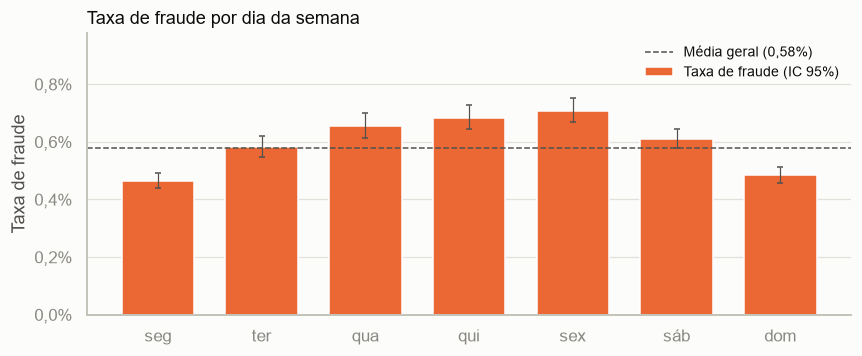

,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Dia,,,,,,
seg,254.282,1.182,"0,46%","0,44% a 0,49%","0,8","15,7%"
ter,160.227,935,"0,58%","0,55% a 0,62%","1,0","12,5%"
qua,131.073,859,"0,66%","0,61% a 0,70%","1,1","11,4%"
qui,147.285,1.008,"0,68%","0,64% a 0,73%","1,2","13,4%"
sex,152.272,1.079,"0,71%","0,67% a 0,75%","1,2","14,4%"
sáb,200.957,1.227,"0,61%","0,58% a 0,65%","1,1","16,3%"
dom,250.579,1.216,"0,49%","0,46% a 0,51%","0,8","16,2%"


In [7]:
by_weekday = fraud_rate_by(transactions, "weekday")

fig, ax = plt.subplots(figsize=(8, 3.4))
rate_bars(ax, by_weekday, WEEKDAYS)
ax.set_title("Taxa de fraude por dia da semana")
ax.set_ylabel("Taxa de fraude")
fig.tight_layout()
plt.show()

display(show_rates(by_weekday.rename(index=dict(enumerate(WEEKDAYS))), "Dia"))

O dia da semana tem um efeito pequeno. A quantidade de fraudes por dia é parecida (de 859 a
1.227), mas o volume varia de 131 mil transações (quarta) a 254 mil (segunda). Por isso a taxa
vai de **0,46% na segunda a 0,71% na sexta**, e a diferença vem principalmente do denominador.
É um sinal fraco: pode entrar no modelo, mas não é prioridade.

## 7. Análise por categoria comercial

,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Categoria,,,,,,
shopping_net,97.543,1.713,"1,76%","1,68% a 1,84%","3,0","22,8%"
misc_net,63.287,915,"1,45%","1,36% a 1,54%","2,5","12,2%"
grocery_pos,123.638,1.743,"1,41%","1,35% a 1,48%","2,4","23,2%"
shopping_pos,116.672,843,"0,72%","0,68% a 0,77%","1,2","11,2%"
gas_transport,131.659,618,"0,47%","0,43% a 0,51%","0,8","8,2%"
misc_pos,79.655,250,"0,31%","0,28% a 0,36%","0,5","3,3%"
grocery_net,45.452,134,"0,29%","0,25% a 0,35%","0,5","1,8%"
travel,40.507,116,"0,29%","0,24% a 0,34%","0,5","1,5%"
entertainment,94.014,233,"0,25%","0,22% a 0,28%","0,4","3,1%"


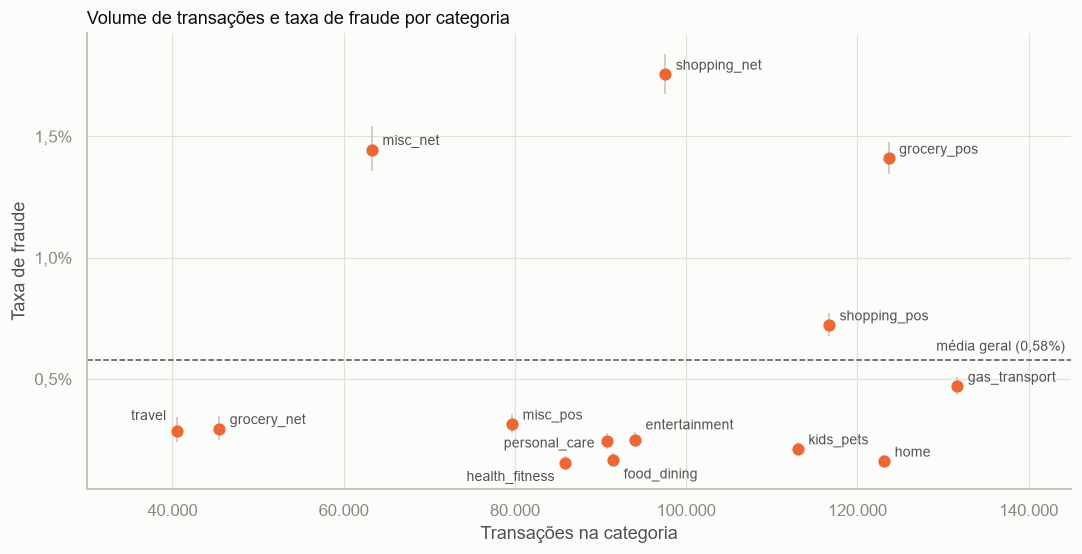

As 3 categorias de maior taxa têm 21,9% das transações e 58,2% das fraudes


In [8]:
by_category = fraud_rate_by(transactions, "category").sort_values("rate", ascending=False)
display(show_rates(by_category, "Categoria"))

fig, ax = plt.subplots(figsize=(10, 5.2))
errors = [by_category["rate"] - by_category["low"], by_category["high"] - by_category["rate"]]
ax.errorbar(by_category["transactions"], by_category["rate"], yerr=errors, fmt="o",
            color=FRAUD_COLOR, ecolor=AXIS, elinewidth=1, markersize=7)
# Labels of the four categories that sit close together are pushed apart by hand.
LABEL_OFFSETS = {"personal_care": (-8, -4), "entertainment": (7, 7), "health_fitness": (-7, -12),
                 "food_dining": (7, -12), "travel": (-7, 7)}
for name, row in by_category.iterrows():
    dx, dy = LABEL_OFFSETS.get(name, (7, 3))
    ax.annotate(name, (row["transactions"], row["rate"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=INK_SECONDARY,
                ha="right" if dx < 0 else "left")
ax.axhline(OVERALL_RATE, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.annotate(f"média geral ({fmt_pct(OVERALL_RATE)})", xy=(1, OVERALL_RATE),
            xycoords=("axes fraction", "data"), xytext=(-4, 4), textcoords="offset points",
            ha="right", va="bottom", fontsize=9, color=INK_SECONDARY)
ax.set_title("Volume de transações e taxa de fraude por categoria")
ax.set_xlabel("Transações na categoria")
ax.set_ylabel("Taxa de fraude")
thousands_axis(ax, "x")
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.005))
percent_axis(ax)
ax.set_xlim(30_000, 145_000)
fig.tight_layout()
plt.show()

top_three = by_category.head(3)
share_of_transactions = top_three["transactions"].sum() / len(transactions)
share_of_frauds = top_three["frauds"].sum() / TOTAL_FRAUDS
print(f"As 3 categorias de maior taxa têm {fmt_pct(share_of_transactions, 1)} das transações e "
      f"{fmt_pct(share_of_frauds, 1)} das fraudes")

Três categorias se destacam: **`shopping_net` (1,76%, 3 vezes a média), `misc_net` (1,45%) e
`grocery_pos` (1,41%)**. Juntas, elas têm 21,9% das transações e 58,2% das fraudes.

O gráfico mostra por que quantidade e taxa precisam ser vistas separadas:

- `gas_transport` é a categoria com mais transações (131.659), mas tem taxa de 0,47%, abaixo
  da média;
- `grocery_pos` tem a maior quantidade de fraudes (1.743) *e* uma das maiores taxas.

As menores taxas ficam em `health_fitness` (0,15%), `home` (0,16%) e `food_dining` (0,17%).
Toda categoria tem pelo menos 116 fraudes, então os intervalos de confiança são estreitos.

Comprar pela internet não é sempre mais arriscado:

- `shopping_net` (1,76%) supera `shopping_pos` (0,72%), e `misc_net` (1,45%) supera
  `misc_pos` (0,31%);
- mas em supermercado é o contrário: `grocery_pos` tem 1,41% e `grocery_net`, 0,29%.

Uma regra simples como "online é suspeito" erraria.

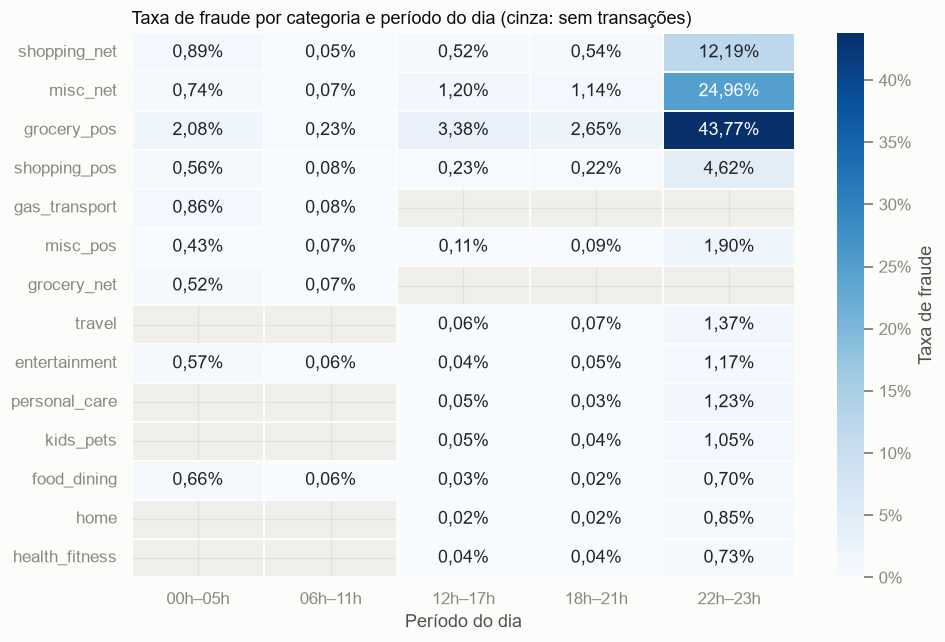

period,00h–05h,06h–11h,12h–17h,18h–21h,22h–23h
category,,,,,
shopping_net,20.657,20.612,27.676,18.124,10.474
misc_net,25.833,25.658,5.568,3.844,2.384
grocery_pos,61.229,60.013,1.037,717,642
shopping_pos,22.456,22.893,35.518,23.590,12.215
gas_transport,65.981,65.678,0,0,0
misc_pos,22.736,22.804,17.021,11.295,5.799
grocery_net,22.800,22.652,0,0,0
travel,0,0,20.144,13.508,6.855
entertainment,8.140,8.232,38.740,25.830,13.072


In [9]:
PERIODS = ["00h–05h", "06h–11h", "12h–17h", "18h–21h", "22h–23h"]
transactions["period"] = pd.cut(transactions["hour"], [-1, 5, 11, 17, 21, 23], labels=PERIODS)
period_counts = transactions.pivot_table(index="category", columns="period", values="is_fraud",
                                         aggfunc="size", observed=False).reindex(by_category.index)
period_rates = transactions.pivot_table(index="category", columns="period", values="is_fraud",
                                        aggfunc="mean", observed=False).reindex(by_category.index)

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(period_rates, mask=period_counts.fillna(0).eq(0), cmap="Blues", vmin=0,
            annot=period_rates.map(lambda value: "" if pd.isna(value) else fmt_pct(value, 2)),
            fmt="", linewidths=1, linecolor=SURFACE, cbar_kws={"label": "Taxa de fraude"}, ax=ax)
ax.set_facecolor(EMPTY)
ax.collections[0].colorbar.formatter = mticker.FuncFormatter(lambda value, _: fmt_pct(value, 0))
ax.collections[0].colorbar.update_ticks()
ax.set_title("Taxa de fraude por categoria e período do dia (cinza: sem transações)")
ax.set_xlabel("Período do dia")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

display(period_counts.map(fmt_int))

Cruzar categoria e horário revela duas coisas.

**Um artefato da simulação.** As células cinzas não têm nenhuma transação:

- `gas_transport` e `grocery_net` só aparecem entre 0h e 11h;
- `health_fitness`, `home`, `kids_pets`, `personal_care` e `travel` só aparecem entre 12h e
  23h;
- `grocery_pos` tem 121 mil transações de madrugada e de manhã e só 2.396 à tarde e à noite.

Na vida real nada impede uma compra de combustível à noite. É assim que a simulação gera os
dados, e é isso que causa o degrau de volume visto na seção 6.

**Uma interação forte.** O risco depende da combinação entre categoria e horário, não de cada
um separado. Entre 22h e 23h:

- **43,8% das 642 transações de `grocery_pos` são fraude**;
- em `misc_net` são 25,0%, e em `shopping_net`, 12,2%.

Nas mesmas categorias, a taxa despenca entre 6h e 11h: 0,23% em `grocery_pos`, 0,07% em
`misc_net` e 0,05% em `shopping_net`. Um modelo de árvores (LightGBM) capta esse tipo de
combinação sozinho; uma regressão logística precisa recebê-la explicitamente.

## 8. Análise por valor

,Legítima,Fraude
Média,"67,67","531,32"
Desvio padrão,"154,01","390,56"
Mínimo,"1,00","1,06"
1%,"1,26","6,79"
5%,"2,44","9,10"
25%,"9,61","245,66"
Mediana,"47,28","396,50"
75%,"82,54","900,88"
95%,"189,90","1.083,99"
99%,"486,30","1.179,69"


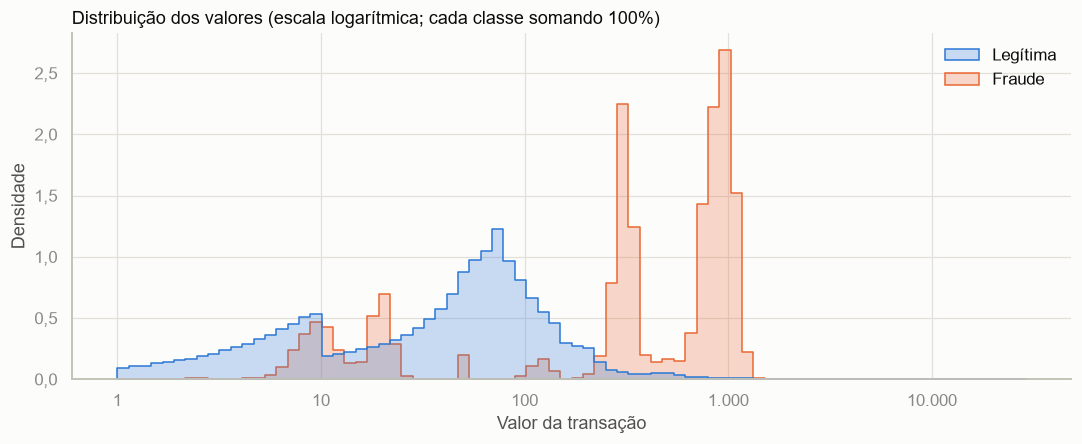

In [10]:
quantiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
amount_summary = (
    transactions.groupby("is_fraud")["amount"].describe(percentiles=quantiles).T.drop(index="count")
)
amount_summary.columns = [CLASS_LABELS[column] for column in amount_summary.columns]
amount_summary.index = ["Média", "Desvio padrão", "Mínimo", "1%", "5%", "25%", "Mediana", "75%",
                        "95%", "99%", "Máximo"]
display(amount_summary.map(fmt_dec))

amounts = transactions[["amount"]].assign(Classe=transactions["is_fraud"].map(CLASS_LABELS))
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.histplot(data=amounts, x="amount", hue="Classe", hue_order=["Legítima", "Fraude"],
             palette=CLASS_COLORS, log_scale=True, bins=80, stat="density", common_norm=False,
             element="step", alpha=0.25, ax=ax)
ax.set_title("Distribuição dos valores (escala logarítmica; cada classe somando 100%)")
ax.set_xlabel("Valor da transação")
ax.set_ylabel("Densidade")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: fmt_int(value)))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: fmt_dec(value, 1)))
ax.get_legend().set_title("")
fig.tight_layout()
plt.show()

Os valores das duas classes são muito diferentes:

- **legítimas:** mediana de 47,28 e média de 67,67, com uma cauda longa que chega a 28.948,90;
- **fraudes:** mediana de **396,50** e média de 531,32, e metade delas fica entre 245,66 e
  900,88.

O histograma mostra que a fraude tem **dois grupos**:

- valores pequenos, perto de 10 (5% das fraudes ficam abaixo de 9,10);
- valores altos, entre cerca de 200 e 1.376,04, que é a maior fraude da base.

Os valores estão na unidade da base; os dados simulam cidades dos Estados Unidos.

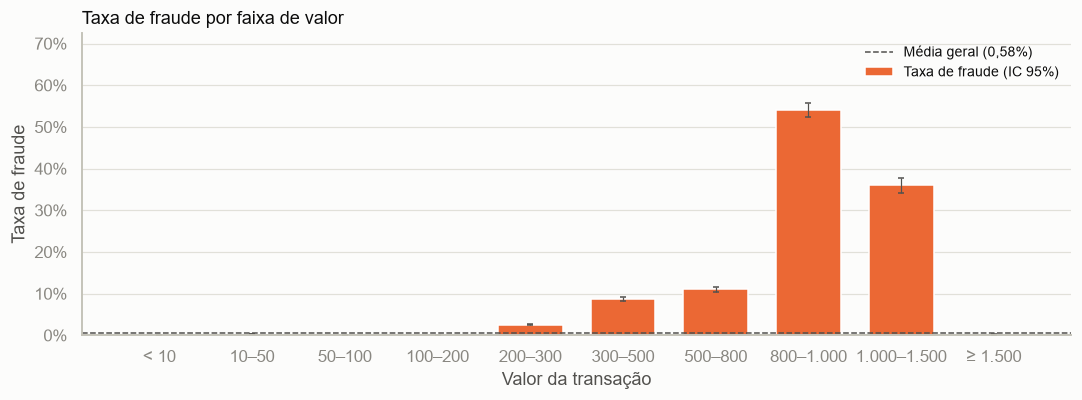

,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Faixa de valor,,,,,,
< 10,335.718,525,"0,16%","0,14% a 0,17%","0,3","7,0%"
10–50,336.496,1.082,"0,32%","0,30% a 0,34%","0,6","14,4%"
50–100,389.514,45,"0,01%","0,01% a 0,02%","0,0","0,6%"
100–200,173.017,150,"0,09%","0,07% a 0,10%","0,1","2,0%"
200–300,31.631,795,"2,51%","2,35% a 2,69%","4,3","10,6%"
300–500,14.668,1.261,"8,60%","8,15% a 9,06%","14,9","16,8%"
500–800,8.413,924,"10,98%","10,33% a 11,67%","19,0","12,3%"
800–1.000,3.281,1.774,"54,07%","52,36% a 55,77%","93,4","23,6%"
1.000–1.500,2.641,950,"35,97%","34,16% a 37,82%","62,1","12,7%"


Maior fraude: 1.376,04. Transações acima desse valor: 1.575, nenhuma fraude.


In [11]:
AMOUNT_BANDS = [0, 10, 50, 100, 200, 300, 500, 800, 1000, 1500, np.inf]
band_labels = ["< 10", "10–50", "50–100", "100–200", "200–300", "300–500", "500–800",
               "800–1.000", "1.000–1.500", "≥ 1.500"]
transactions["amount_band"] = pd.cut(transactions["amount"], AMOUNT_BANDS, right=False,
                                     labels=band_labels)
by_amount = fraud_rate_by(transactions, "amount_band")

fig, ax = plt.subplots(figsize=(10, 3.8))
rate_bars(ax, by_amount, band_labels)
ax.set_title("Taxa de fraude por faixa de valor")
ax.set_xlabel("Valor da transação")
ax.set_ylabel("Taxa de fraude")
percent_axis(ax, places=0)
fig.tight_layout()
plt.show()

display(show_rates(by_amount, "Faixa de valor"))
largest_fraud = transactions.loc[transactions["is_fraud"].eq(1), "amount"].max()
above = transactions["amount"].gt(largest_fraud)
print(f"Maior fraude: {fmt_dec(largest_fraud)}. Transações acima desse valor: "
      f"{fmt_int(above.sum())}, nenhuma fraude.")

A taxa de fraude sobe muito a partir de 200:

| Faixa de valor | Taxa de fraude |
| --- | --- |
| 200 a 300 | 2,5% |
| 300 a 500 | 8,6% |
| 500 a 800 | 11,0% |
| 800 a 1.000 | **54,1%** |
| 1.000 a 1.500 | 36,0% |

Na faixa de 50 a 100, onde estão 389.514 transações, há só 45 fraudes (0,01%).

**Artefato da simulação:** nenhuma fraude passa de 1.376,04. As 1.575 transações acima desse
valor são todas legítimas. Um modelo aprenderia que "valor muito alto é seguro", o que seria
perigoso com dados reais. A ficha do modelo precisa registrar esse limite.

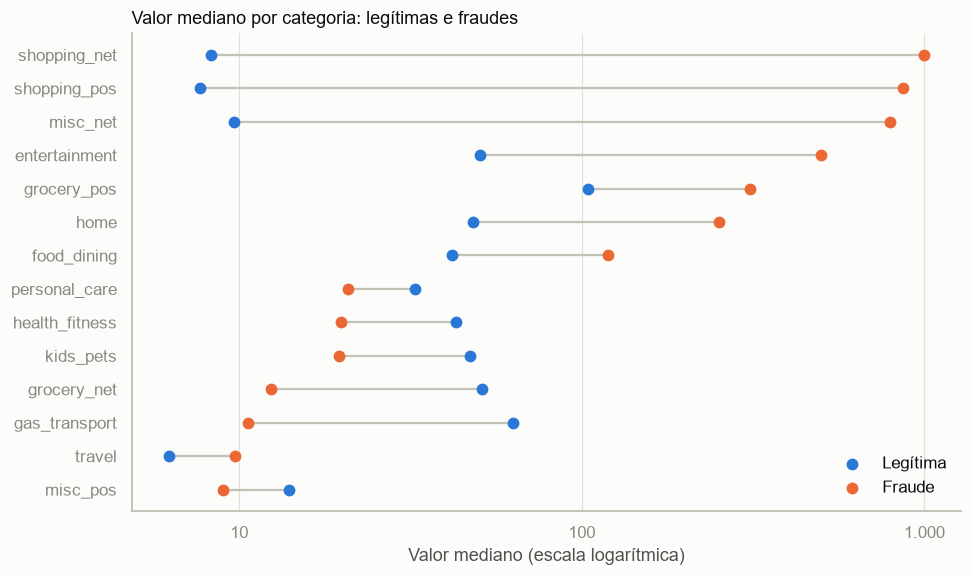

In [12]:
category_medians = (
    transactions.groupby(["category", "is_fraud"])["amount"].median().unstack("is_fraud")
    .rename(columns=CLASS_LABELS).sort_values("Fraude")
)
fig, ax = plt.subplots(figsize=(9, 5.4))
rows = np.arange(len(category_medians))
ax.hlines(rows, category_medians["Legítima"], category_medians["Fraude"], color=AXIS,
          linewidth=1.5)
for label in ("Legítima", "Fraude"):
    ax.scatter(category_medians[label], rows, color=CLASS_COLORS[label], s=45, zorder=3, label=label)
ax.set_yticks(rows, category_medians.index)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: fmt_int(value)))
ax.set_title("Valor mediano por categoria: legítimas e fraudes")
ax.set_xlabel("Valor mediano (escala logarítmica)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

O sentido da diferença de valor depende da categoria.

**Fraude muito mais cara que a compra legítima:**

| Categoria | Mediana da fraude | Mediana da legítima |
| --- | ---: | ---: |
| `shopping_net` | 995,57 | 8,30 |
| `shopping_pos` | 867,76 | 7,71 |
| `misc_net` | 792,33 | 9,68 |

**Fraude *mais barata* que a compra legítima:**

| Categoria | Mediana da fraude | Mediana da legítima |
| --- | ---: | ---: |
| `gas_transport` | 10,64 | 62,93 |
| `grocery_net` | 12,36 | 50,99 |
| `health_fitness` | 19,80 | 42,94 |

Esse segundo grupo explica os valores pequenos do histograma. Por isso o valor sozinho não basta:
ele precisa ser lido junto com a categoria e, como mostra a seção 10, junto com o que é normal
para aquele cartão.

## 9. Análise de distância geográfica

A distância é calculada em linha reta, sobre a superfície da Terra (fórmula de Haversine), entre
as coordenadas do cliente (`lat`, `long`) e as do lojista (`merch_lat`, `merch_long`).

,Legítima,Fraude
Média,"76,1","76,3"
Desvio padrão,"29,1","28,8"
Mínimo,"0,0","0,7"
5%,"24,7","25,6"
25%,"55,3","55,6"
Mediana,"78,2","77,9"
75%,"98,5","98,4"
95%,"120,5","120,2"
Máximo,"152,1","144,5"


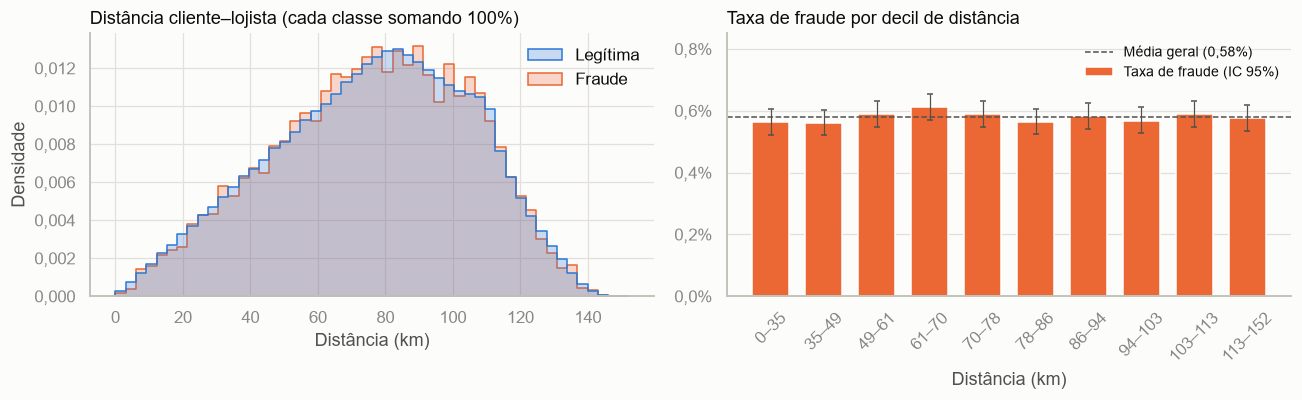

In [13]:
def haversine_km(lat1, lon1, lat2, lon2) -> np.ndarray:
    """Great-circle distance in km between two arrays of coordinates in degrees."""
    lat1, lon1, lat2, lon2 = (
        np.radians(np.asarray(values, float)) for values in (lat1, lon1, lat2, lon2)
    )
    half_chord = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(half_chord))


transactions["distance_km"] = haversine_km(transactions["lat"], transactions["long"],
                                           transactions["merch_lat"], transactions["merch_long"])
distance_summary = transactions.groupby("is_fraud")["distance_km"].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.drop(index="count")
distance_summary.columns = [CLASS_LABELS[column] for column in distance_summary.columns]
distance_summary.index = ["Média", "Desvio padrão", "Mínimo", "5%", "25%", "Mediana", "75%", "95%",
                          "Máximo"]
display(distance_summary.map(lambda value: fmt_dec(value, 1)))

transactions["distance_decile"] = pd.qcut(transactions["distance_km"], 10)
by_distance = fraud_rate_by(transactions, "distance_decile")
decile_labels = [
    f"{fmt_int(interval.left)}–{fmt_int(interval.right)}" for interval in by_distance.index
]

fig, (ax_hist, ax_rate) = plt.subplots(1, 2, figsize=(12, 3.8))
distances = transactions[["distance_km"]].assign(Classe=transactions["is_fraud"].map(CLASS_LABELS))
sns.histplot(data=distances, x="distance_km", hue="Classe", hue_order=["Legítima", "Fraude"],
             palette=CLASS_COLORS, bins=50, stat="density", common_norm=False, element="step",
             alpha=0.25, ax=ax_hist)
ax_hist.set_title("Distância cliente–lojista (cada classe somando 100%)")
ax_hist.set_xlabel("Distância (km)")
ax_hist.set_ylabel("Densidade")
ax_hist.yaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: fmt_dec(value, 3)))
ax_hist.get_legend().set_title("")
rate_bars(ax_rate, by_distance, decile_labels)
ax_rate.set_title("Taxa de fraude por decil de distância")
ax_rate.set_xlabel("Distância (km)")
ax_rate.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

**A distância não separa fraude de compra legítima nesta base:**

- as medianas são praticamente iguais (78,2 km nas legítimas e 77,9 km nas fraudes), e os
  percentis de 5% e 95% também;
- a taxa de fraude fica entre 0,56% e 0,61% em todos os decis, com lift de 0,97 a 1,06 e
  intervalos de confiança que se sobrepõem.

Nenhuma transação fica a mais de 153 km do cliente, e as duas distribuições têm o mesmo formato.
Isso sugere que a simulação posiciona o lojista perto do endereço do cliente sem relação com a
fraude, mas os dados não permitem confirmar esse mecanismo.

**Limitações da medida:**

- é a distância em linha reta até o endereço cadastrado, não o deslocamento real do cliente;
- em compras pela internet (`*_net`) a "localização do lojista" não tem significado físico.

Em dados reais, a distância e a mudança de lugar entre compras costumam ser sinais úteis. Aqui,
a expectativa é que contribuam pouco ou nada.

## 10. Comportamento histórico dos cartões

### Como o histórico é calculado sem olhar para o futuro

As transações já estão ordenadas por cartão e por data e hora (seção 3). Para cada transação,
os sinais abaixo usam **só as transações anteriores do mesmo cartão**:

| Sinal | Cálculo |
| --- | --- |
| Transações anteriores na base | contagem acumulada (`cumcount`), que não inclui a própria transação |
| Horas desde a compra anterior | diferença para a transação anterior (`diff`) |
| Valor médio das compras anteriores | soma acumulada menos a transação atual, dividida pelas anteriores; é o mesmo que `shift(1).expanding().mean()` (conferido abaixo) |
| Valor em relação à média do cartão | valor da transação dividido pela média anterior |
| Compras e valor gasto na última 1 h, 24 h e 7 dias | transações com horário em [t − janela, t), sem contar a atual |
| Primeira compra do cartão na categoria | a combinação cartão + categoria aparece pela primeira vez |

O rótulo de fraude das transações anteriores **nunca** é usado. Na vida real, a confirmação de
uma fraude chega dias ou semanas depois, por contestação do cliente, e não está disponível no
momento da decisão.

In [14]:
def card_history(frame: pd.DataFrame) -> pd.DataFrame:
    """History signals of each transaction, computed only from earlier transactions of its card.

    The frame must be sorted by card_id and timestamp (stable sort, decision D6).
    """
    by_card = frame.groupby("card_id", sort=False)
    history = pd.DataFrame(index=frame.index)
    history["previous_transactions"] = by_card.cumcount()
    history["hours_since_previous"] = by_card["timestamp"].diff().dt.total_seconds() / 3600
    previous_total = by_card["amount"].cumsum() - frame["amount"]
    history["previous_mean_amount"] = (
        previous_total / history["previous_transactions"]
    ).where(history["previous_transactions"] > 0)
    history["amount_ratio"] = frame["amount"] / history["previous_mean_amount"]

    # One sorted key per (card, second): a window [t - w, t) is a range of positions before the
    # current row, found with a binary search. Cards are 10**9 seconds apart, so windows never
    # cross from one card into another.
    seconds = ((frame["timestamp"] - pd.Timestamp("2019-01-01")) // pd.Timedelta(seconds=1))
    key = frame["card_id"].to_numpy(np.int64) * 10**9 + seconds.to_numpy(np.int64)
    if np.any(np.diff(key) < 0):
        raise ValueError("frame must be sorted by card_id and timestamp")
    position = np.arange(len(frame))
    running_amount = np.concatenate([[0.0], np.cumsum(frame["amount"].to_numpy())])
    for name, window_seconds in {"1h": 3_600, "24h": 86_400, "7d": 7 * 86_400}.items():
        start = np.searchsorted(key, key - window_seconds, side="left")
        history[f"transactions_last_{name}"] = position - start
        history[f"amount_last_{name}"] = running_amount[position] - running_amount[start]
    history["new_category_for_card"] = ~frame.duplicated(["card_id", "category"])
    return history


history = card_history(transactions)
transactions = transactions.join(history)

# Check 1: the previous mean equals the shift(1) + expanding mean suggested for this analysis.
reference_mean = transactions.groupby("card_id")["amount"].transform(
    lambda amounts: amounts.shift(1).expanding().mean())
assert np.allclose(transactions["previous_mean_amount"], reference_mean, equal_nan=True)

# Check 2: the window counts and sums equal a brute-force count over earlier rows, on 3 cards.
for card in transactions["card_id"].drop_duplicates().sample(3, random_state=7):
    rows = transactions[transactions["card_id"].eq(card)]
    times = rows["timestamp"].to_numpy()
    values = rows["amount"].to_numpy()
    earlier = np.tri(len(rows), k=-1, dtype=bool)  # earlier[i, j]: row j comes before row i
    inside = times[None, :] >= times[:, None] - np.timedelta64(24, "h")
    window = earlier & inside
    assert np.array_equal(window.sum(axis=1), rows["transactions_last_24h"].to_numpy())
    assert np.allclose(window @ values, rows["amount_last_24h"].to_numpy())
print("Verificações do histórico: OK (sem uso de informação futura)")

Verificações do histórico: OK (sem uso de informação futura)


As duas verificações passaram:

- a média anterior é idêntica à calculada com `shift(1).expanding().mean()`;
- as contagens e somas das janelas batem com uma contagem por força bruta, que só considera
  transações anteriores, em três cartões sorteados.

### Como as fraudes se agrupam no cartão

In [15]:
frauds = transactions[transactions["is_fraud"].eq(1)]
episodes = frauds.groupby("card_id").agg(frauds=("is_fraud", "size"), start=("timestamp", "min"),
                                         end=("timestamp", "max"))
episodes["days"] = (episodes["end"] - episodes["start"]).dt.total_seconds() / 86_400
largest_gap_days = frauds.groupby("card_id")["timestamp"].diff().max() / pd.Timedelta(days=1)

windows = transactions.join(episodes[["start", "end"]], on="card_id", how="inner")
during = windows[windows["timestamp"].between(windows["start"], windows["end"])]
after = windows[windows["timestamp"].gt(windows["end"])]

episode_summary = pd.Series(
    {
        "Cartões no arquivo de treino": fmt_int(transactions["card_id"].nunique()),
        "Cartões com fraude": fmt_int(len(episodes)),
        "Maior intervalo entre duas fraudes do mesmo cartão (dias)": fmt_dec(largest_gap_days, 2),
        "Fraudes por cartão (mediana, mínimo e máximo)":
            f"{fmt_int(episodes['frauds'].median())} ({fmt_int(episodes['frauds'].min())} a "
            f"{fmt_int(episodes['frauds'].max())})",
        "Duração do episódio em dias (mediana e máximo)":
            f"{fmt_dec(episodes['days'].median())} (máximo {fmt_dec(episodes['days'].max())})",
        "Transações do cartão durante o episódio": fmt_int(len(during)),
        "... que são fraude": fmt_pct(during["is_fraud"].mean()),
        "Cartões que continuam comprando depois do episódio": fmt_int(after["card_id"].nunique()),
    },
    name="Episódios de fraude",
)
display(episode_summary.to_frame())

,Episódios de fraude
Cartões no arquivo de treino,983
Cartões com fraude,762
Maior intervalo entre duas fraudes do mesmo cartão (dias),"1,79"
"Fraudes por cartão (mediana, mínimo e máximo)",10 (2 a 19)
Duração do episódio em dias (mediana e máximo),"1,88 (máximo 2,89)"
Transações do cartão durante o episódio,7.507
... que são fraude,"99,99%"
Cartões que continuam comprando depois do episódio,682


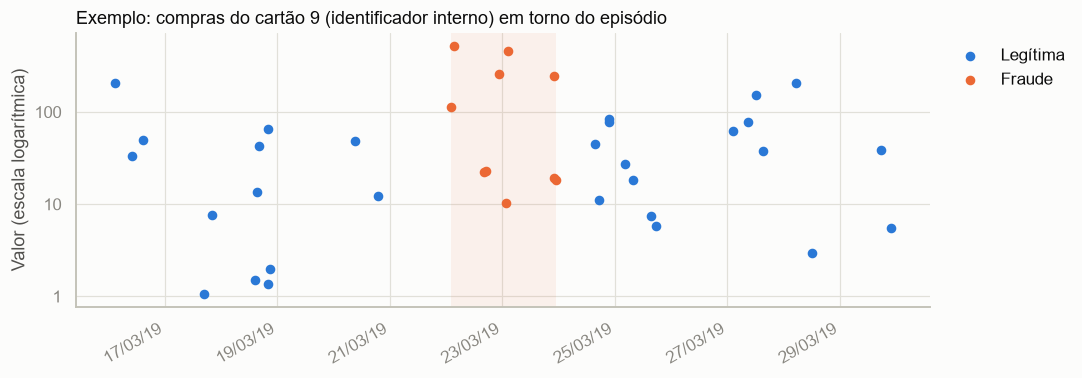

In [16]:
example_card = episodes.index[episodes["frauds"].eq(episodes["frauds"].median())][0]
example = transactions[transactions["card_id"].eq(example_card)]
start, end = episodes.loc[example_card, ["start", "end"]]
margin = pd.Timedelta(days=6)
example = example[example["timestamp"].between(start - margin, end + margin)]

fig, ax = plt.subplots(figsize=(10, 3.6))
for value, label in CLASS_LABELS.items():
    points = example[example["is_fraud"].eq(value)]
    ax.scatter(points["timestamp"], points["amount"], color=CLASS_COLORS[label], s=28, label=label,
               zorder=3)
ax.axvspan(start, end, color=FRAUD_COLOR, alpha=0.08, linewidth=0)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: fmt_int(value)))
ax.set_title(f"Exemplo: compras do cartão {example_card} (identificador interno) em torno do "
             "episódio")
ax.set_ylabel("Valor (escala logarítmica)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

As fraudes desta base acontecem em **episódios curtos e concentrados**:

- 762 dos 983 cartões (77,5%) sofrem fraude no arquivo de treino, e cada um tem **um único
  episódio**: duas fraudes do mesmo cartão nunca ficam a mais de 1,79 dia uma da outra;
- o episódio típico tem 10 fraudes (de 2 a 19) e dura 1,88 dia (no máximo, 2,89);
- **durante o episódio, o cartão praticamente só faz fraudes**: das 7.507 transações dentro
  desses intervalos, só uma é legítima;
- 682 cartões voltam a comprar normalmente depois. A simulação não bloqueia o cartão.

O gráfico mostra o padrão num cartão típico: compras pequenas e espaçadas, uma rajada de compras
altas em menos de dois dias e a volta ao normal.

In [17]:
HISTORY_SIGNALS = {
    "amount": "Valor da transação",
    "amount_ratio": "Valor ÷ média anterior do cartão",
    "hours_since_previous": "Horas desde a compra anterior",
    "transactions_last_1h": "Compras na última 1 h",
    "transactions_last_24h": "Compras nas últimas 24 h",
    "amount_last_24h": "Valor gasto nas últimas 24 h",
    "transactions_last_7d": "Compras nos últimos 7 dias",
    "previous_transactions": "Transações anteriores na base",
}
by_class = transactions.groupby("is_fraud")[list(HISTORY_SIGNALS)]
medians, p90 = by_class.median(), by_class.quantile(0.9)
comparison = pd.DataFrame(
    {
        "Mediana · legítima": medians.loc[0],
        "Mediana · fraude": medians.loc[1],
        "Percentil 90 · legítima": p90.loc[0],
        "Percentil 90 · fraude": p90.loc[1],
    }
).rename(index=HISTORY_SIGNALS)
display(comparison.map(fmt_dec))

,Mediana · legítima,Mediana · fraude,Percentil 90 · legítima,Percentil 90 · fraude
Valor da transação,"47,28","396,50","134,21","1.024,59"
Valor ÷ média anterior do cartão,"0,66","5,23","2,01","15,40"
Horas desde a compra anterior,"4,62","1,36","21,73","19,32"
Compras na última 1 h,"0,00","0,00","1,00","2,00"
Compras nas últimas 24 h,"3,00","4,00","8,00","7,00"
Valor gasto nas últimas 24 h,"171,14","1.674,16","598,43","4.056,83"
Compras nos últimos 7 dias,"23,00","17,00","43,00","32,00"
Transações anteriores na base,"779,00","438,00","1.903,00","1.483,50"


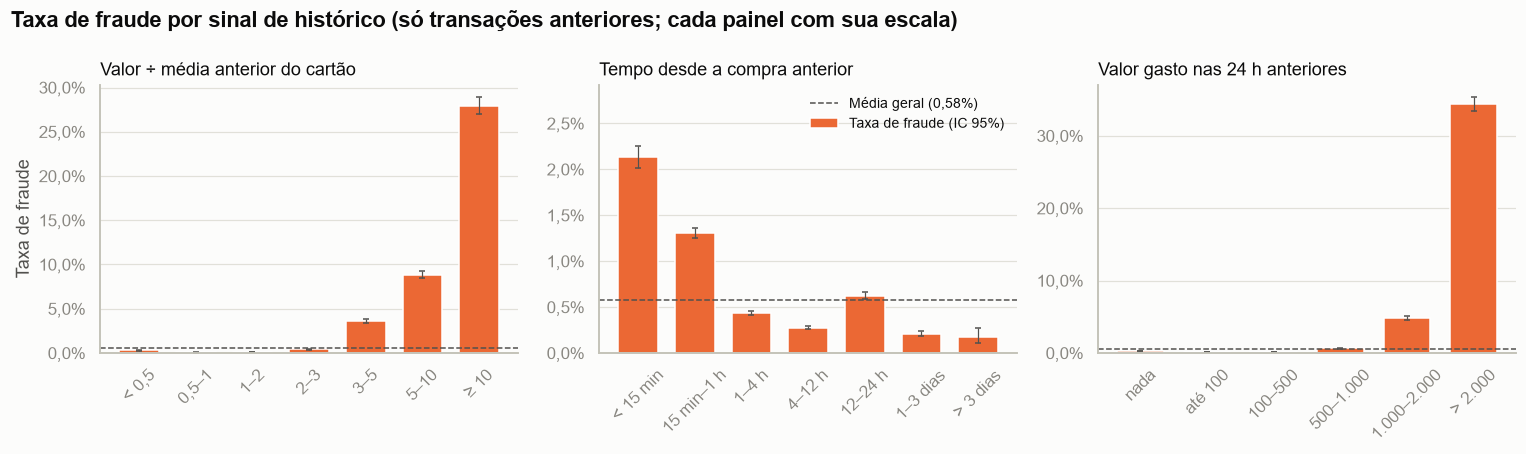

,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Valor ÷ média anterior,,,,,,
"< 0,5",544.741,1.589,"0,29%","0,28% a 0,31%","0,5","21,2%"
"0,5–1",327.285,204,"0,06%","0,05% a 0,07%","0,1","2,7%"
1–2,287.780,408,"0,14%","0,13% a 0,16%","0,2","5,4%"
2–3,82.923,347,"0,42%","0,38% a 0,46%","0,7","4,6%"
3–5,28.406,1.027,"3,62%","3,40% a 3,84%","6,2","13,7%"
5–10,15.750,1.395,"8,86%","8,42% a 9,31%","15,3","18,6%"
≥ 10,8.807,2.461,"27,94%","27,02% a 28,89%","48,3","32,8%"


,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Tempo desde a anterior,,,,,,
< 15 min,59.539,1.268,"2,13%","2,02% a 2,25%","3,7","16,9%"
15 min–1 h,152.974,1.998,"1,31%","1,25% a 1,36%","2,3","26,6%"
1–4 h,384.085,1.655,"0,43%","0,41% a 0,45%","0,7","22,0%"
4–12 h,398.602,1.085,"0,27%","0,26% a 0,29%","0,5","14,5%"
12–24 h,192.552,1.201,"0,62%","0,59% a 0,66%","1,1","16,0%"
1–3 dias,98.499,208,"0,21%","0,18% a 0,24%","0,4","2,8%"
> 3 dias,9.441,16,"0,17%","0,10% a 0,28%","0,3","0,2%"


,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Gasto nas 24 h anteriores,,,,,,
nada,108.919,299,"0,27%","0,25% a 0,31%","0,5","4,0%"
até 100,330.025,445,"0,13%","0,12% a 0,15%","0,2","5,9%"
100–500,672.266,869,"0,13%","0,12% a 0,14%","0,2","11,6%"
500–1.000,139.391,892,"0,64%","0,60% a 0,68%","1,1","11,9%"
1.000–2.000,36.673,1.772,"4,83%","4,62% a 5,06%","8,3","23,6%"
> 2.000,9.401,3.229,"34,35%","33,39% a 35,31%","59,3","43,0%"


In [18]:
RATIO_BANDS = [0, 0.5, 1, 2, 3, 5, 10, np.inf]
ratio_labels = ["< 0,5", "0,5–1", "1–2", "2–3", "3–5", "5–10", "≥ 10"]
GAP_BANDS = [0, 0.25, 1, 4, 12, 24, 72, np.inf]
gap_labels = ["< 15 min", "15 min–1 h", "1–4 h", "4–12 h", "12–24 h", "1–3 dias", "> 3 dias"]
SPENT_BANDS = [-0.01, 0, 100, 500, 1000, 2000, np.inf]
spent_labels = ["nada", "até 100", "100–500", "500–1.000", "1.000–2.000", "> 2.000"]

banded = transactions.assign(
    ratio_band=pd.cut(transactions["amount_ratio"], RATIO_BANDS, right=False,
                      labels=ratio_labels),
    gap_band=pd.cut(transactions["hours_since_previous"], GAP_BANDS, right=False,
                    labels=gap_labels),
    spent_band=pd.cut(transactions["amount_last_24h"], SPENT_BANDS, labels=spent_labels),
)
by_ratio = fraud_rate_by(banded, "ratio_band")
by_gap = fraud_rate_by(banded, "gap_band")
by_spent = fraud_rate_by(banded, "spent_band")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, table, labels, title in (
    (axes[0], by_ratio, ratio_labels, "Valor ÷ média anterior do cartão"),
    (axes[1], by_gap, gap_labels, "Tempo desde a compra anterior"),
    (axes[2], by_spent, spent_labels, "Valor gasto nas 24 h anteriores"),
):
    rate_bars(ax, table, labels, legend=ax is axes[1])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Taxa de fraude")
fig.suptitle("Taxa de fraude por sinal de histórico (só transações anteriores; cada painel com "
             "sua escala)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

for title, table in (("Valor ÷ média anterior", by_ratio), ("Tempo desde a anterior", by_gap),
                     ("Gasto nas 24 h anteriores", by_spent)):
    display(show_rates(table, title))

Três sinais de histórico se destacam.

**Valor em relação ao que é normal para o cartão.** A fraude típica vale 5,23 vezes a média das
compras anteriores do cartão; a compra legítima típica vale 0,66 vez.

- quando o valor é pelo menos **10 vezes a média, 27,9% das transações são fraude** (48 vezes a
  média geral), e essa faixa reúne 32,8% de todas as fraudes;
- entre 5 e 10 vezes, a taxa é de 8,9%;
- abaixo de 3 vezes, não passa de 0,42%.

**Pouco tempo desde a compra anterior.** Compras a menos de 15 minutos da anterior têm taxa de
2,13% (3,7 vezes a média), e entre 15 minutos e 1 hora, de 1,31%. A mediana é de 1,36 h nas
fraudes e de 4,62 h nas legítimas.

**Muito dinheiro gasto nas 24 horas anteriores.** Quando o cartão já gastou mais de 2.000 no dia
anterior, **34,4% das transações são fraude** (59 vezes a média), e essa faixa reúne 43,0% das
fraudes. A mediana é de 1.674,16 nas fraudes e de 171,14 nas legítimas.

Outros sinais ajudam pouco ou enganam:

- **a quantidade de compras nas últimas 24 h** quase não muda (mediana de 4 nas fraudes e de 3
  nas legítimas);
- **"transações anteriores na base"** é menor nas fraudes, mas só mede há quanto tempo o cartão
  aparece no arquivo, que começa em 01/01/2019. Não é um comportamento do cliente e não deve
  ser usado como está.

In [19]:
by_new_category = fraud_rate_by(transactions, "new_category_for_card").rename(
    index={False: "categoria já usada pelo cartão", True: "primeira compra na categoria"})
display(show_rates(by_new_category, "Categoria para o cartão"))
first_in_category = transactions.loc[transactions["new_category_for_card"], "timestamp"]
early = first_in_category.lt(transactions["timestamp"].min() + pd.Timedelta(days=30)).mean()
print(f"Primeiras compras na categoria feitas nos 30 primeiros dias do arquivo: "
      f"{fmt_pct(early, 1)}")

,Transações,Fraudes,Taxa de fraude,IC 95%,Lift,% das fraudes
Categoria para o cartão,,,,,,
categoria já usada pelo cartão,1.283.587,7.042,"0,55%","0,54% a 0,56%","0,9","93,8%"
primeira compra na categoria,13.088,464,"3,55%","3,24% a 3,88%","6,1","6,2%"


Primeiras compras na categoria feitas nos 30 primeiros dias do arquivo: 86,5%


A primeira compra de um cartão numa categoria tem taxa de **3,55%, contra 0,55%** quando a
categoria já é conhecida: 6,1 vezes a média. O efeito é forte, mas cobre só 6,2% das fraudes.

Além disso, 86,5% dessas "primeiras compras" acontecem nos 30 primeiros dias do arquivo, quando
nenhum cartão tem histórico. Parte do efeito vem do corte da base, não do comportamento.

In [20]:
episode_order = frauds.groupby("card_id").cumcount()
first_frauds = frauds[episode_order.eq(0)]
later_frauds = frauds[episode_order.gt(0)]
legit = transactions[transactions["is_fraud"].eq(0)]
signals = ["amount", "amount_ratio", "hours_since_previous", "transactions_last_24h",
           "amount_last_24h"]
first_vs_later = pd.DataFrame(
    {
        "Legítimas": legit[signals].median(),
        "1ª fraude do episódio": first_frauds[signals].median(),
        "Fraudes seguintes": later_frauds[signals].median(),
    }
).rename(index=HISTORY_SIGNALS)
first_vs_later.loc["Entre 22h e 3h59"] = [
    group["hour"].isin(NIGHT_HOURS).mean() for group in (legit, first_frauds, later_frauds)
]
shown = first_vs_later.map(fmt_dec)
shown.loc["Entre 22h e 3h59"] = first_vs_later.loc["Entre 22h e 3h59"].map(
    lambda value: fmt_pct(value, 1))
display(shown)
cold_start = first_frauds["previous_transactions"].eq(0).sum()
print(f"Episódios que começam na primeira transação do cartão na base: {fmt_int(cold_start)} de "
      f"{fmt_int(len(first_frauds))}")

,Legítimas,1ª fraude do episódio,Fraudes seguintes
Valor da transação,"47,28","310,54","557,31"
Valor ÷ média anterior do cartão,"0,66","5,08","5,26"
Horas desde a compra anterior,"4,62","12,13","1,08"
Compras nas últimas 24 h,"3,00","1,00","4,00"
Valor gasto nas últimas 24 h,"171,14","38,71","1.921,77"
Entre 22h e 3h59,"23,2%","86,4%","84,6%"


Episódios que começam na primeira transação do cartão na base: 75 de 762


Separar **a primeira fraude de cada episódio** das seguintes muda a leitura dos sinais.

| Sinal (mediana) | 1ª fraude do episódio | Fraudes seguintes |
| --- | --- | --- |
| Valor gasto nas 24 h anteriores | 38,71 | 1.921,77 |
| Horas desde a compra anterior | 12,13 | 1,08 |
| Valor ÷ média anterior | 5,08 | 5,26 |
| Entre 22h e 3h59 | 86,4% | 84,6% |

- **O gasto nas 24 h anteriores e o tempo curto desde a compra anterior detectam a
  *continuação* do episódio**, não o seu início. Na primeira fraude, o gasto anterior é baixo e
  o intervalo desde a compra anterior é até *maior* que o das compras legítimas (12,13 h contra
  4,62 h), porque a atividade normal do cartão para quando o episódio começa.
- **O valor acima do normal para o cartão e o horário noturno aparecem já na primeira fraude**:
  são os sinais que podem pegar o episódio no começo, quando o prejuízo ainda é pequeno.
- Em 75 dos 762 episódios, a primeira fraude é a primeira transação do cartão na base, sem
  nenhum histórico para comparar.

Há ainda um alerta: na vida real, um cartão costuma ser bloqueado depois das primeiras fraudes
confirmadas, e as "fraudes seguintes" talvez nem existissem. Os sinais que só funcionam na
continuação do episódio tendem a parecer melhores nesta base do que seriam na prática.

## 11. Principais descobertas

Todas as taxas abaixo vêm do arquivo de treino (01/01/2019 a 21/06/2020).

1. **A fraude é rara:** 7.506 em 1.296.675 transações (0,58%), uma para cada 172 legítimas. A
   taxa mensal varia de 0,38% a 1,04%, mais pelo volume de transações do que pelo ritmo das
   fraudes.
2. **O horário é o sinal temporal mais forte:** 84,8% das fraudes acontecem entre 22h e 3h59,
   contra 23,2% das compras legítimas. Às 22h e às 23h, a taxa chega a quase 5 vezes a média. O
   dia da semana pesa pouco.
3. **Três categorias concentram as fraudes:** `shopping_net`, `misc_net` e `grocery_pos` reúnem
   58,2% das fraudes com 21,9% das transações. A combinação com o horário é decisiva: entre 22h
   e 23h, 43,8% das transações de `grocery_pos` são fraude.
4. **O valor separa bem, mas depende da categoria:**
   - a mediana é de 396,50 nas fraudes e de 47,28 nas legítimas, e entre 800 e 1.000 a taxa
     chega a 54,1%;
   - em `shopping_net`, `shopping_pos` e `misc_net` a fraude é muito mais cara que a compra
     normal; em `gas_transport`, `grocery_net` e `health_fitness`, é mais barata.
5. **A distância não mostrou sinal:** a taxa fica entre 0,56% e 0,61% em todos os decis de
   distância.
6. **O histórico do cartão traz os sinais mais fortes:**
   - um valor 10 vezes acima da média anterior do cartão tem taxa de 27,9%;
   - mais de 2.000 gastos nas 24 h anteriores, 34,4%;
   - uma compra a menos de 15 minutos da anterior, 2,13%.
7. **As fraudes vêm em episódios:** um por cartão, com cerca de 10 fraudes em menos de 2 dias, e
   durante o episódio o cartão quase só faz fraudes.
8. **A primeira fraude do episódio é diferente das seguintes:** o gasto recente e o tempo desde
   a compra anterior só denunciam a continuação; o valor acima do normal e o horário aparecem já
   no início.

## 12. Limitações da análise

**Da base:**

- **Dados simulados.** As transações foram geradas pela ferramenta Sparkov, imitando cidades dos
  Estados Unidos em 2019 e 2020. Os padrões podem não representar fraudes reais nem o mercado
  brasileiro, com Pix, boletos e golpes de engenharia social, que esta base não cobre.
- **Artefatos da simulação.** Algumas descobertas são regras do gerador, não comportamento:
  - categorias com horário fixo;
  - nenhuma fraude acima de 1.376,04;
  - um único episódio por cartão;
  - atividade legítima interrompida durante o episódio;
  - nenhum bloqueio de cartão.

  Um modelo treinado aqui vai aprender essas regras, e a ficha do modelo precisa registrá-las.

**Do método:**

- **Só o arquivo de treino.** O arquivo de teste não foi analisado de propósito, para continuar
  servindo como avaliação final.
- **Intervalos de confiança otimistas.** O método de Wilson supõe transações independentes, mas
  as fraudes vêm em episódios de cerca de 10 transações do mesmo cartão. O número de eventos
  independentes está mais perto de 762 episódios do que de 7.506 fraudes, e os intervalos reais
  são mais largos que os mostrados.
- **Associação não é causa.** Uma taxa alta num grupo mostra que as duas coisas aparecem juntas,
  não que uma provoca a outra.
- **Distância aproximada.** É a linha reta até o endereço cadastrado, não o deslocamento real.
- **Rótulos imediatos.** Na base, toda transação já vem marcada como fraude ou não. Na prática a
  confirmação demora, e por isso nenhum sinal de histórico usa o rótulo de transações
  anteriores.
- **Começo do arquivo.** Contagens acumuladas e "primeira compra na categoria" dependem de
  quando a base começa (01/01/2019), não só do comportamento do cartão.
- **Atributos pessoais fora.** Gênero, idade e profissão não foram analisados como sinais de
  fraude (decisão D5). Eles entram só na auditoria de viés da fase 4.

## 13. Conclusão e direcionamento para Machine Learning

A análise mostra que dá para separar fraudes de compras legítimas, e que os sinais mais úteis
combinam **o que** se compra (categoria e valor), **quando** (horário) e **o quanto isso foge do
normal do cartão** (histórico). Para a próxima fase:

**Divisão dos dados**

- Divisão temporal dentro do arquivo de treino: treino nos meses mais antigos e validação nos
  mais recentes.
- O arquivo de teste fica para a avaliação final.
- Os mesmos cartões aparecem nos dois arquivos, então a avaliação deve ser lida por período.

**Métricas**

- PR-AUC, revocação com precisão fixa e custo dos erros. A acurácia de quem aprova tudo já é
  99,42%.
- Revocação na **primeira fraude de cada episódio**, que mede a capacidade de interromper o
  prejuízo cedo.

**Sinais candidatos, em ordem de prioridade**

1. Valor em relação à média anterior do cartão.
2. Valor gasto e quantidade de compras nas janelas de 1 h, 24 h e 7 dias anteriores.
3. Tempo desde a compra anterior.
4. Hora do dia, e a combinação de hora com categoria.
5. Categoria e a combinação de categoria com valor.
6. Primeira compra na categoria e dia da semana, com prioridade baixa.
7. Distância, que não mostrou sinal aqui: entra só para confirmar se o modelo a ignora.

**O que não usar**

- O rótulo de transações anteriores.
- A coluna `unix_time` (decisão D6).
- A contagem de "transações anteriores na base" como está.
- Atributos pessoais (decisão D5).

**Cuidados**

- Registrar na ficha do modelo o limite artificial de valor das fraudes.
- Aplicar a regra de desempate da D6 para transações do mesmo cartão no mesmo segundo.
- Lembrar que os sinais de continuação de episódio tendem a parecer melhores aqui do que seriam
  com bloqueio real de cartão.